# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "#89CFF0"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#ff8da1"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#40E0D0"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:purple"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [65]:
import os
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter

# 1) baixa o dataset e vê os arquivos que vieram
path = kagglehub.dataset_download("srisyra02/spotify-music-artist-streaming-analytics")

arquivos = []
for raiz, _, files in os.walk(path):
    for f in files:
        arquivos.append(os.path.relpath(os.path.join(raiz, f), path))

print("Arquivos encontrados:", arquivos)

# 2) pega o primeiro csv (ou troca pelo nome que você quiser)
nome_arquivo = next(f for f in arquivos if f.endswith(".csv"))
print("Carregando:", nome_arquivo)

# 3) carrega no pandas
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "srisyra02/spotify-music-artist-streaming-analytics",
    nome_arquivo,
)

print(df.shape)
df.head()

Arquivos encontrados: ['Spotify Streaming Performance Dataset.csv']
Carregando: Spotify Streaming Performance Dataset.csv
(500, 14)


,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams (in millions),Lead Streams (in millions),Feature Streams (in millions),Solo Streams (in millions),% of Solo Streams,Collaborative Streams (in millions),% of Collaborative Streams
0,Drake,Male,Canada,English,Hip-Hop,Solo,2006,137492.1,94851.1,42640.9,53323.9,38.783246,84168.2,61.216754
1,Taylor Swift,Female,United States,English,Pop,Solo,2006,127861.0,126177.3,1683.8,113421.5,88.706877,14439.5,11.293123
2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013,125899.8,82189.3,43710.5,48887.0,38.830086,77012.8,61.169914
3,The Weeknd,Male,Canada,English,R&B,Solo,2009,95703.2,77189.4,18513.8,51020.0,53.310652,44683.2,46.689348
4,Justin Bieber,Male,Canada,English,Pop,Solo,2009,78104.4,48316.2,29788.2,29638.3,37.947030,48466.1,62.052970


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [66]:
df.shape

(500, 14)

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Artist Name                          500 non-null    object 
 1   Sex                                  500 non-null    object 
 2   Country of Origin                    500 non-null    object 
 3   Primary Language                     500 non-null    object 
 4   Primary Genre                        500 non-null    object 
 5    Artist Type                         500 non-null    object 
 6   Debut Year                           500 non-null    int64  
 7   Total Streams (in millions)          500 non-null    float64
 8   Lead Streams (in millions)           500 non-null    float64
 9   Feature Streams (in millions)        500 non-null    float64
 10  Solo Streams (in millions)           500 non-null    float64
 11  % of Solo Streams               

In [68]:
df.describe()

,Debut Year,Total Streams (in millions),Lead Streams (in millions),Feature Streams (in millions),Solo Streams (in millions),% of Solo Streams,Collaborative Streams (in millions),% of Collaborative Streams
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2005.346000,16817.610200,12141.734000,4681.289000,8324.397600,50.613084,8493.212600,49.386916
std,13.312578,14845.197632,11844.675186,5952.827762,9589.010168,33.762147,9612.491536,33.762147
min,1939.000000,6972.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2001.750000,8768.175000,6489.750000,696.500000,2519.775000,20.117951,2015.650000,16.860219
50%,2009.000000,11923.250000,8716.350000,3005.600000,6472.950000,47.062829,6592.250000,52.937171
75%,2014.000000,18020.050000,13456.900000,6093.350000,10115.550000,83.139781,11019.575000,79.882049
max,2023.000000,137492.100000,126177.300000,43710.500000,113421.500000,100.000000,84168.200000,100.000000


### Duplicadas

In [69]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

Neste dataset, vamos criar uma variável alvo binária chamada `performance`. Definiremos como 'Alta' se o `Total Streams (in millions)` estiver acima da mediana, e 'Baixa' caso contrário. Esta será a distinção que usaremos nas cores ao longo da aula (rosa = Baixa Performance, turquesa = Alta Performance).

In [70]:
import numpy as np

corte = df["Total Streams (in millions)"].median()

df["performance"] = np.where(df["Total Streams (in millions)"] > corte, "Alta", "Baixa")
df["performance"].value_counts()

performance
Alta     250
Baixa    250
Name: count, dtype: int64

## 2. Dados Faltantes

In [71]:
df.isna().sum()

Artist Name                            0
Sex                                    0
Country of Origin                      0
Primary Language                       0
Primary Genre                          0
 Artist Type                           0
Debut Year                             0
Total Streams (in millions)            0
Lead Streams (in millions)             0
Feature Streams (in millions)          0
Solo Streams (in millions)             0
% of Solo Streams                      0
Collaborative Streams (in millions)    0
% of Collaborative Streams             0
performance                            0
dtype: int64

**Discussao:** Alguma feature tem dados ausentes nos seus dados?


*Resposta*:  Todos os dados

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset de `Spotify Streaming Performance`, não foram encontrados dados ausentes (`df.isna().sum()` resultou em zeros para todas as colunas). Portanto, a discussão sobre a natureza e o mecanismo de ausência de dados não é aplicável neste caso. Isso simplifica a etapa de tratamento de dados ausentes.

Com base na análise de `df.isna().sum()`, concluímos que o dataset de desempenho de streaming do Spotify **não possui dados ausentes** em nenhuma de suas colunas. Isso simplifica significativamente a fase de pré-processamento, pois não há necessidade de aplicar técnicas de imputação ou remoção de linhas devido a valores faltantes. Diferente de outros datasets que poderiam exigir discussões aprofundadas sobre mecanismos de ausência (MCAR/MAR/MNAR), aqui podemos prosseguir diretamente para a análise distribucional e de outliers, conforme a estrutura da EDA.

**As ausências ocorrem juntas?**

Como não há dados ausentes no nosso conjunto de dados, não é necessário analisar se as ausências ocorrem juntas. Esta etapa seria relevante apenas se houvesse valores faltantes em pelo menos duas colunas.

In [72]:
print("Nao tem ausencia")


Nao tem ausencia


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

In [73]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()

if len(cols_com_ausentes) < 2:
    print("Não há colunas com dados ausentes ou não há pelo menos duas colunas com ausências para analisar co-ocorrência.")
else:
    tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
                rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title("As ausências ocorrem juntas?")
    plt.tight_layout()
    plt.show()

Não há colunas com dados ausentes ou não há pelo menos duas colunas com ausências para analisar co-ocorrência.


**Pra discutir:** Como não foram encontrados dados ausentes, não há discussão sobre linhas com ausências ou o mecanismo de ausência (MCAR/MAR/MNAR). Essa parte da análise é pulada para este dataset.

A discussão sobre mecanismos de ausência (MCAR: Mecanismo Completamente Aleatório, MAR: Mecanismo Aleatório, MNAR: Mecanismo Não Aleatório) é relevante apenas quando há dados faltantes. No nosso caso, como o dataset não apresenta ausências, não se aplica a necessidade de decidir entre esses mecanismos.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. Para o dataset de Spotify, como não há ausências, essa etapa foi simplificada.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [74]:
VARS_QUANT = ["Debut Year", "Total Streams (in millions)", "Lead Streams (in millions)", "Feature Streams (in millions)", "Solo Streams (in millions)"]
VARS_QUALI = ["Sex", "Country of Origin", "Primary Language", "Primary Genre", " Artist Type", "performance"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Debut Year,2005.35,2009.00,13.31,1939.00,2023.00,-1.78,3.45
Total Streams (in millions),16817.61,11923.25,14845.20,6972.00,137492.10,4.00,22.75
Lead Streams (in millions),12141.73,8716.35,11844.68,0.00,126177.30,4.17,26.71
Feature Streams (in millions),4681.29,3005.60,5952.83,0.00,43710.50,2.61,9.50
Solo Streams (in millions),8324.40,6472.95,9589.01,0.00,113421.50,4.16,32.17


**Pra discutir:** olhando a tabela de estatísticas descritivas , notamos que `Debut Year` tem uma `skewness` negativa, indicando que a cauda da distribuição está à esquerda (mais artistas antigos que o esperado, ou menos artistas recentes de forma balanceada). Já as variáveis de streams (`Total Streams (in millions)`, `Lead Streams (in millions)`, `Feature Streams (in millions)`, `Solo Streams (in millions)`) apresentam `skewness` e `kurtosis` muito altas (muito acima de 1 e 2, respectivamente). Isso é esperado para dados de streaming, onde alguns artistas podem ter um número massivo de streams (poucos 'hits') enquanto a maioria tem um volume menor? Ou isso sugere a presença de outliers que distorcem a distribuição?

-  Observando as estatísticas descritivas, a `skewness` negativa em `Debut Year` pode indicar que há mais artistas que estrearam há mais tempo do que artistas mais recentes de forma balanceada. Já as variáveis de streams, com `skewness` e `kurtosis` muito altas, parecem ser algo esperado para dados de streaming. Artistas 'hitmakers' podem distorcer a distribuição, gerando poucos valores muito altos (outliers) e muitos valores mais baixos. Isso sugere que os outliers podem ser estatísticos e legítimos, mas talvez precisemos ficar de olho neles.

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


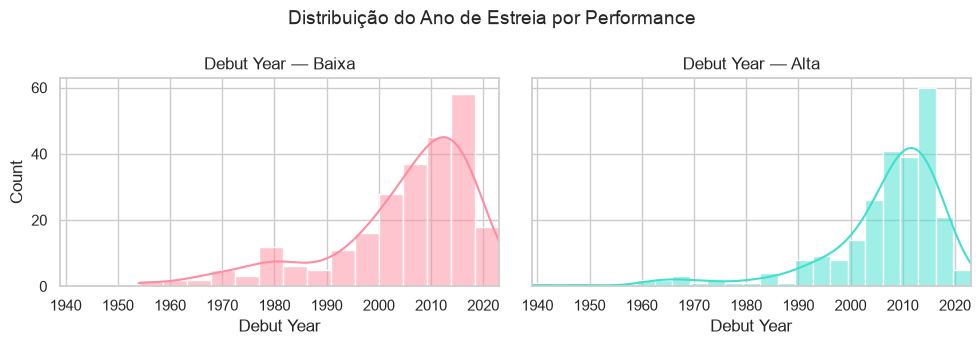

In [75]:
COL = "Debut Year"   # ajusta se o nome for outro

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

lim = (df[COL].min(), df[COL].max())

for j, (classe, cor) in enumerate([("Baixa", COR_CONTEXTO), ("Alta", COR_DESTAQUE)]):
    subset = df[df["performance"] == classe]
    sns.histplot(data=subset, x=COL, kde=True, color=cor, ax=axes[j])
    axes[j].set_xlim(lim)
    axes[j].set_title(f"{COL} — {classe}")

fig.suptitle("Distribuição do Ano de Estreia por Performance", fontsize=14)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), olhando especificamente para o 'Ano de Estreia' : a distribuição do 'Ano de Estreia' parece ter um formato bem diferente entre artistas de 'Baixa Performance' e 'Alta Performance'? Para outras variáveis de streaming (que não estão plotadas aqui, mas podemos imaginar), esperaríamos ver uma diferença mais acentuada?

- Não, o formato parece bem parecido nos dois grupos. Nos dois a maioria dos artistas estreou em anos mais recentes, com uma cauda pra esquerda, então o ano de estreia sozinho não parece separar alta e baixa performance. Já nas variáveis de streams a diferença deve ser bem maior, mas isso já era esperado, porque a performance foi criada a partir do Total Streams, e o Lead e o Solo Streams fazem parte desse total.

#### Testes de Aderência

*Será se o Ano de Estreia segue uma distribuição normal?*

O **Shapiro-Wilk** é o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `Debut Year`.

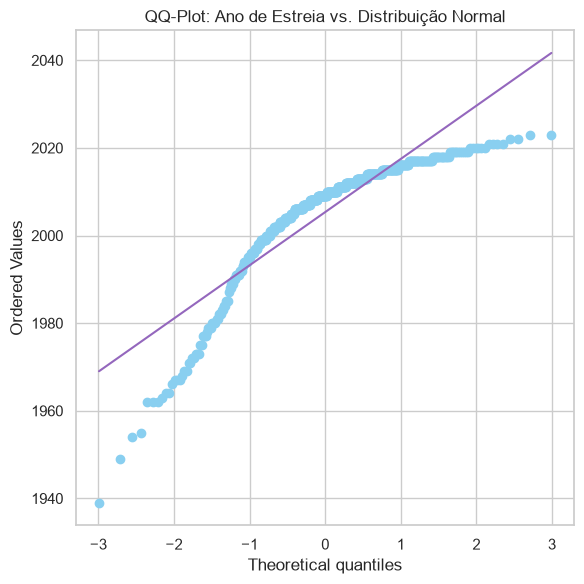

In [76]:
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df[COL].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title(f"QQ-Plot: Ano de Estreia vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [77]:
VARS_QUANT = ["Debut Year", "Total Streams (in millions)", "Lead Streams (in millions)", "Feature Streams (in millions)", "Solo Streams (in millions)"]


resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Debut Year,0.8254,0.0,True
Total Streams (in millions),0.5972,0.0,True
Lead Streams (in millions),0.6366,0.0,True
Feature Streams (in millions),0.7315,0.0,True
Solo Streams (in millions),0.6785,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

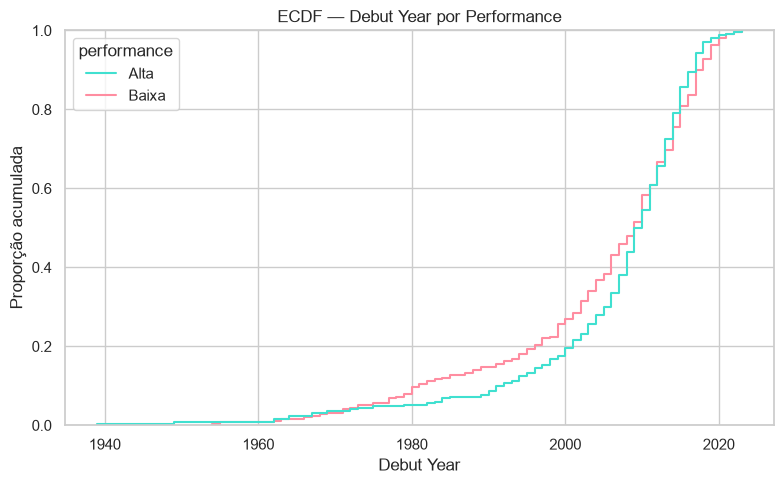

In [78]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x=COL, hue="performance",
             palette={"Baixa": COR_CONTEXTO, "Alta": COR_DESTAQUE})
plt.title(f"ECDF — {COL} por Performance")
plt.xlabel(COL)
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

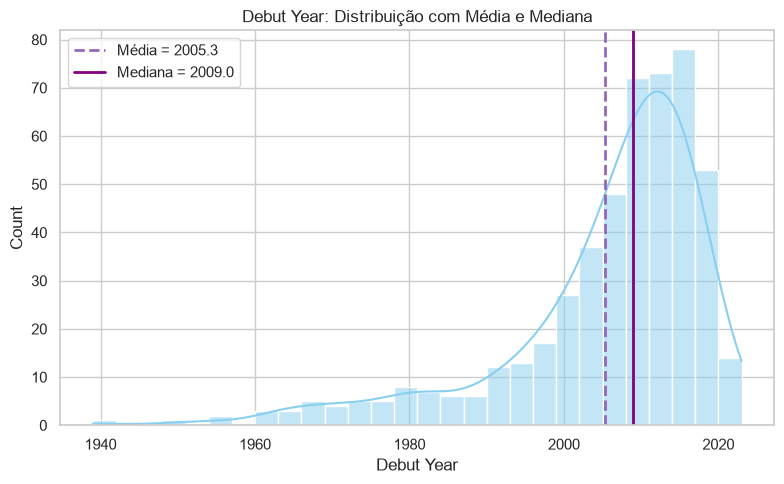

In [79]:
media_COL = df[COL].mean()
mediana_COL = df[COL].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x=COL, kde=True, color=COR_NEUTRA)
plt.axvline(media_COL, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_COL:.1f}")
plt.axvline(mediana_COL, color="purple", linestyle="-", linewidth=2, label=f"Mediana = {mediana_COL:.1f}")
plt.title(f"{COL}: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

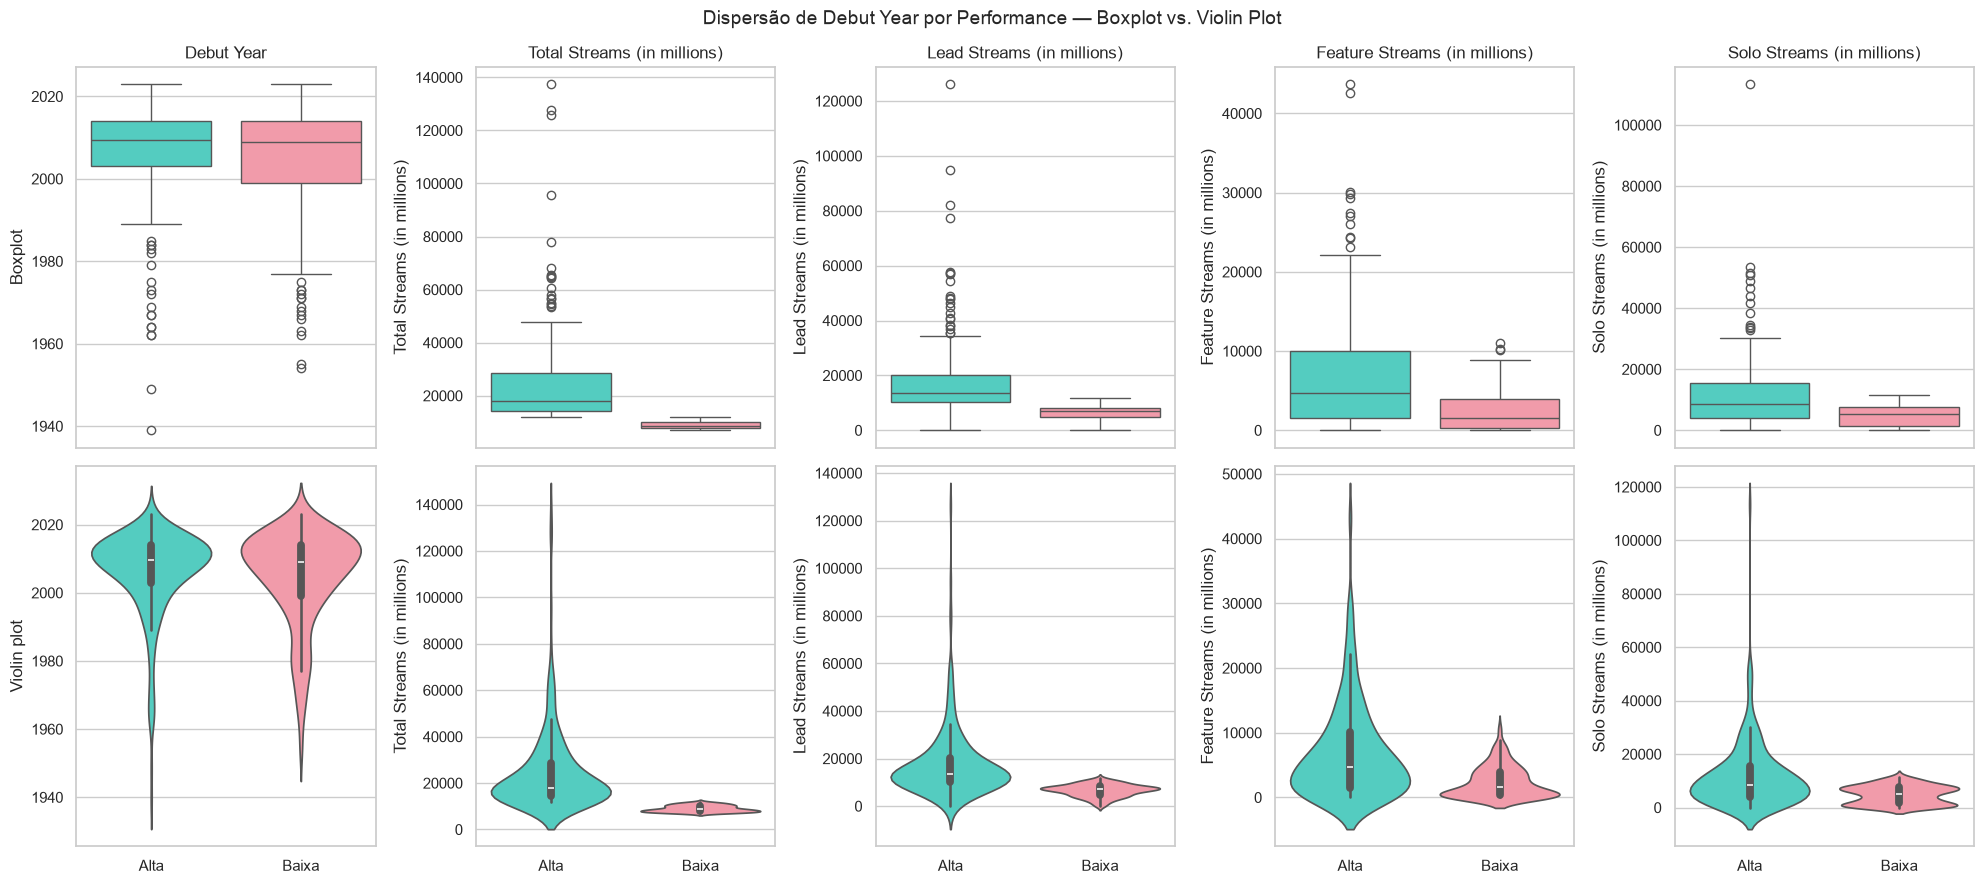

In [80]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_performance = {"Baixa": COR_CONTEXTO, "Alta": COR_DESTAQUE} # Atualizado para categorias de performance

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col_name in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="performance", y=col_name, hue="performance",
                palette=palette_performance, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col_name)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="performance", y=col_name, hue="performance",
                    palette=palette_performance, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")

fig.suptitle(f"Dispersão de {VARS_QUANT[0]} por Performance — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre 'Baixa Performance' e 'Alta Performance'? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

- Sim, olhando os boxplots , as variáveis de streams (como 'Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams') mostram caixas (IQR) bem mais altas para 'Alta Performance' em comparação com 'Baixa Performance'. Isso já indica que essas variáveis são fortes candidatas a diferenciar os dois grupos.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [81]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "Baixa": round(lim_inf, 2),
        "Alta": round(lim_sup, 2),
    }

pd.DataFrame(resumo_outliers).T

,Baixa,Alta
Debut Year,1983.38,2032.38
Total Streams (in millions),-5109.64,31897.86
Lead Streams (in millions),-3960.97,23907.62
Feature Streams (in millions),-7398.78,14188.62
Solo Streams (in millions),-8873.89,21509.21


### Visualizando os Outliers

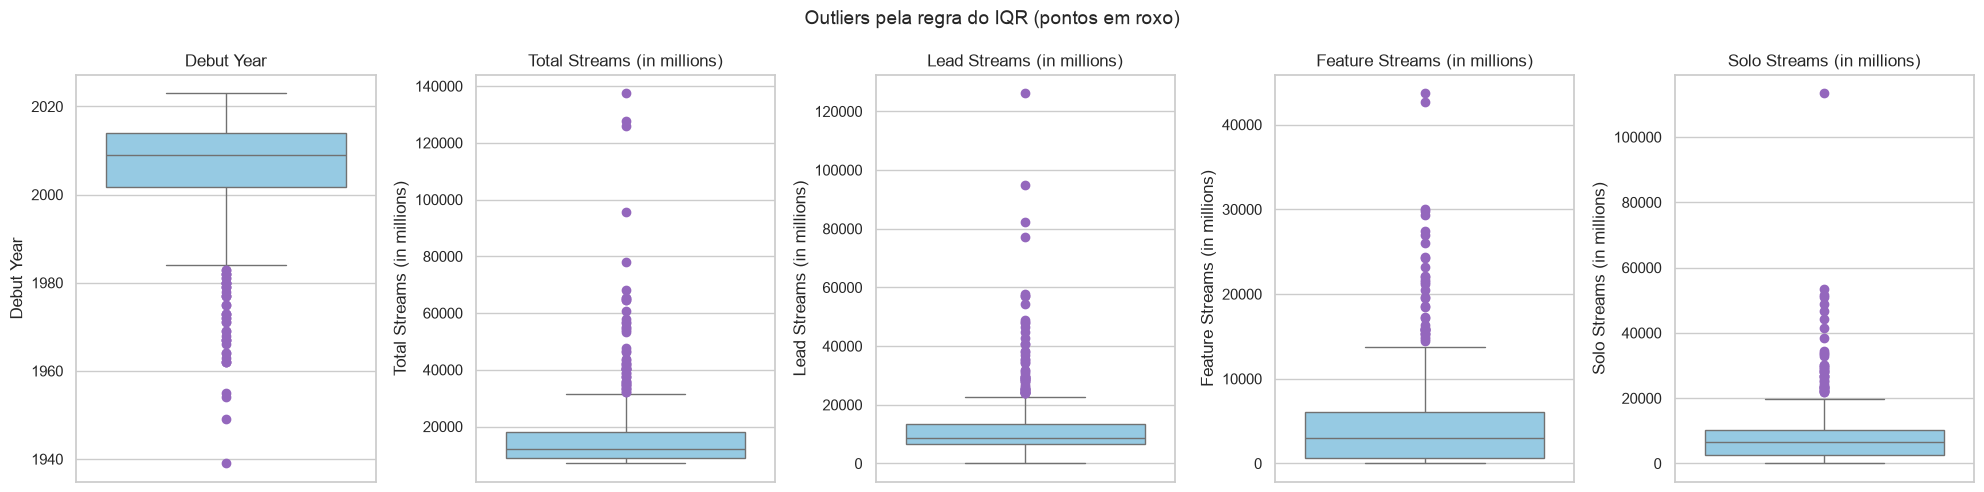

In [82]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em roxo)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** no slide 26 da aula 9, vimos a classificação de outliers em três tipos, cada um com um tratamento sugerido:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |


Ao observar os outliers que apareceram (especialmente em 'Total Streams (in millions)' e 'Solo Streams (in millions)'): será que eles fazem sentido dentro do universo do streaming de música (por exemplo, seriam artistas com um número realmente muito alto de streams)? Ou eles indicam algo que não se encaixa nas regras da plataforma? Pensar nisso é importante para definirmos qual das três categorias se aplica e, consequentemente, se o melhor caminho é manter, transformar ou até mesmo remover esses pontos.

- Os outliers que aparecem, principalmente nas variáveis de streams, fazem bastante sentido no contexto de streaming de música. Existem artistas que realmente atingem milhões ou bilhões de streams, o que os torna 'outliers' estatísticos em relação à maioria dos artistas. Provavelmente, são outliers legítimos ('Estatísticos'), não erros de dados ou violações de regras, mas representam artistas com sucesso estrondoso.

### Decidindo o Tratamento dos Dados Ausentes

No nosso dataset, não foram encontrados dados ausentes. Portanto, não há tratamento a ser realizado nesta seção.

In [83]:
linhas_antes = df.shape[0]
df_antes = df.copy()
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 500 | Linhas depois: 500 | Removidas: 0


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

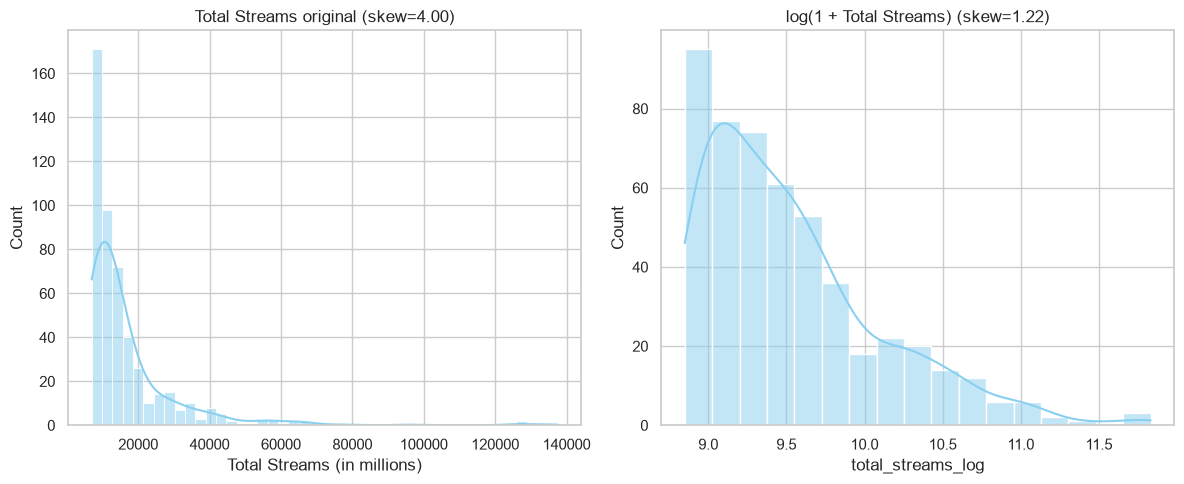

In [84]:
df["total_streams_log"] = np.log1p(df["Total Streams (in millions)"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="Total Streams (in millions)", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Total Streams original (skew={df['Total Streams (in millions)'].skew():.2f})")

sns.histplot(data=df, x="total_streams_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Total Streams) (skew={df['total_streams_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `total_streams_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

- Sim, a transformação logarítmica em 'Total Streams (in millions)'reduziu visivelmente a assimetria. A distribuição original era bem mais 'esticada' para a direita, e a versão logarítmica ficou mais simétrica, parecendo mais próxima de uma normal. Isso é bom se precisarmos de testes que assumam normalidade.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [85]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Debut Year,2005.35,2009.00,13.31,1939.00,2023.00,-1.78,3.45
Total Streams (in millions),16817.61,11923.25,14845.20,6972.00,137492.10,4.00,22.75
Lead Streams (in millions),12141.73,8716.35,11844.68,0.00,126177.30,4.17,26.71
Feature Streams (in millions),4681.29,3005.60,5952.83,0.00,43710.50,2.61,9.50
Solo Streams (in millions),8324.40,6472.95,9589.01,0.00,113421.50,4.16,32.17


### Comparando "antes"x "depois""



In [86]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Debut Year,-1.780,-1.780,3.449,3.449,0.0,0.0
Total Streams (in millions),3.998,3.998,22.748,22.748,0.0,0.0
Lead Streams (in millions),4.170,4.170,26.708,26.708,0.0,0.0
Feature Streams (in millions),2.607,2.607,9.504,9.504,0.0,0.0
Solo Streams (in millions),4.164,4.164,32.165,32.165,0.0,0.0


**Pra discutir:** Os valores mudaram muito? Considerando que não removemos nenhuma linha e decidimos **não** alterar nenhum outlier, é esperado que as métricas descritivas permaneçam inalteradas. Este resultado (pouca mudança) é uma confirmação de que o tratamento foi conservador e não impactou a distribuição geral dos dados.

-  Não, os valores não mudaram quase nada! Como não removemos linhas nem mexemos diretamente nos outliers (apenas fizemos uma transformação logarítmica que não alterou os valores originais no `df`), é totalmente esperado que as estatísticas descritivas (skewness e kurtosis) sejam as mesmas antes e depois. Isso mostra que nossa decisão de manter os outliers não alterou a visão geral dos dados.

**O Ano de Estreia ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [87]:
import pandas as pd
from scipy import stats


stat_sw_antes, p_valor_sw_antes = stats.shapiro(df_antes["Debut Year"].dropna())
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["Debut Year"].dropna())

print(f"Shapiro-Wilk (antes)  — Debut Year: estatística={stat_sw_antes:.4f}, p-valor={p_valor_sw_antes:.4g}")
print(f"Shapiro-Wilk (depois) — Debut Year: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")


Shapiro-Wilk (antes)  — Debut Year: estatística=0.8254, p-valor=6.2e-23
Shapiro-Wilk (depois) — Debut Year: estatística=0.8254, p-valor=6.2e-23


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 ('Total Streams (in millions)' e 'Lead Streams (in millions)'), comparando a versão original (`df_antes`) com a tratada (`df`).

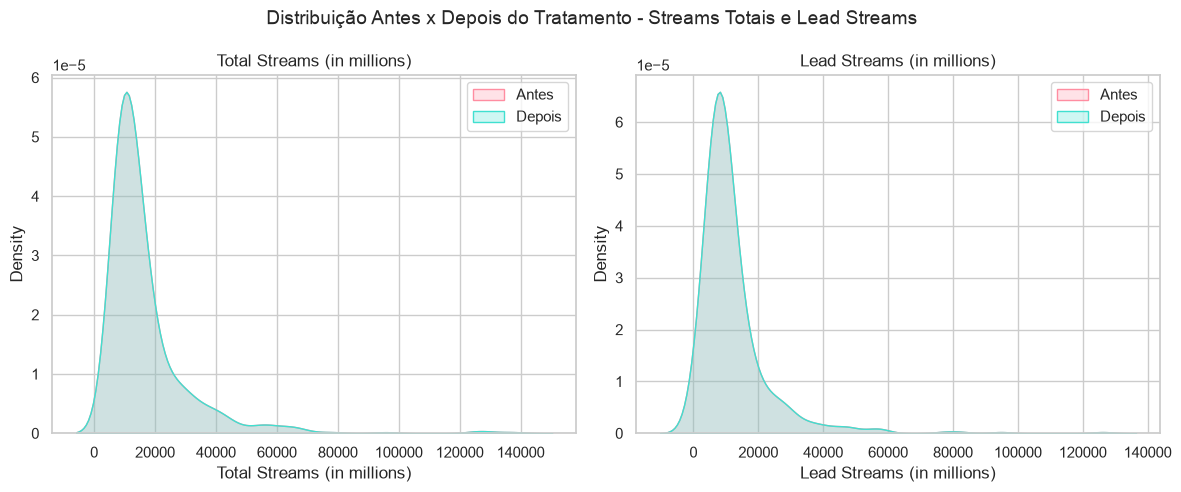

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["Total Streams (in millions)", "Lead Streams (in millions)"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento - Streams Totais e Lead Streams", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas 'antes' e 'depois' praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers. Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem 'antes x depois' que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

- Sim, as curvas 'antes' e 'depois' estão praticamente sobrepostas. Isso é o que se espera, já que não removemos outliers e os dados ausentes não existiam. A transformação logarítmica foi apenas para demonstração e não alterou a distribuição original do `df`. Se tivéssemos feito um tratamento mais agressivo (como remover outliers), veríamos uma diferença maior.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [89]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- Sex ---
        absoluta  relativa
Sex                       
Male         390     0.780
Female        88     0.176
Mixed         22     0.044
\n--- Country of Origin ---
                     absoluta  relativa
Country of Origin                      
United States             265     0.530
United Kingdom             55     0.110
Mexico                     27     0.054
Canada                     18     0.036
Colombia                   16     0.032
Brazil                     15     0.030
India                      13     0.026
South Korea                11     0.022
Argentina                   9     0.018
Australia                   7     0.014
Germany                     7     0.014
Spain                       6     0.012
Sweden                      5     0.010
France                      5     0.010
Ireland                     4     0.008
Italy                       3     0.006
Norway                      2     0.004
Scotland                    2     0.004
Dominican Republic     

#### Visualizando as frequências

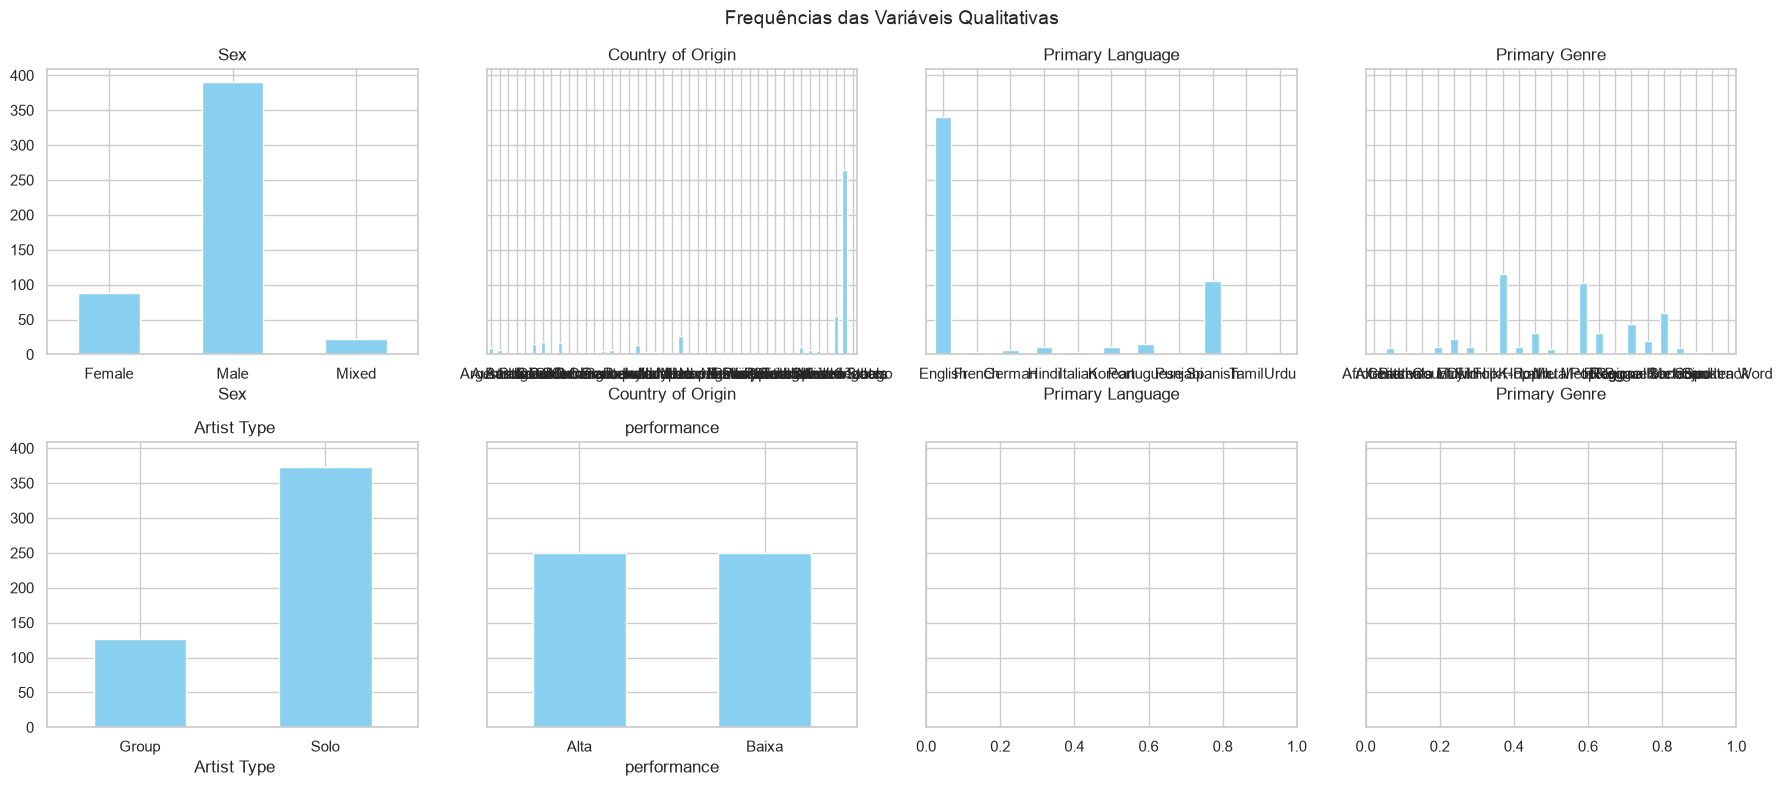

In [90]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

- Sim, algumas variáveis qualitativas parecem bem desbalanceadas. 'Sex' tem bem mais 'Male' do que 'Female' ou 'Mixed'. 'Country of Origin' e 'Primary Language' também mostram um país (EUA) e uma língua (inglês) dominando. Isso é importante, porque se formos cruzar essas variáveis com a performance, o número pequeno de observações em algumas categorias pode dificultar a análise ou mostrar resultados menos confiáveis.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [91]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["performance"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Sex,3.0,17.73,0.580
Country of Origin,43.0,265.00,0.548
Primary Language,11.0,340.00,0.433
Primary Genre,23.0,115.00,0.765
Artist Type,2.0,2.94,0.818
performance,2.0,1.00,1.000


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `performance` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente? (A tabela  mostra que `performance` está perfeitamente balanceada com entropia normalizada de 1.00).
-  A tabela mostra que 'Country of Origin' e 'Primary Language' têm entropia normalizada baixa (0.548 e 0.433), indicando desbalanceamento. 'Sex' e 'Artist Type' também têm um certo desbalanceamento, mas menor. Já o nosso alvo, `performance`, está perfeitamente balanceado com entropia normalizada de 1.00 e razão de desbalanceamento de 1.00, o que é ótimo para a análise!

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

Matriz de Correlação — Kendall


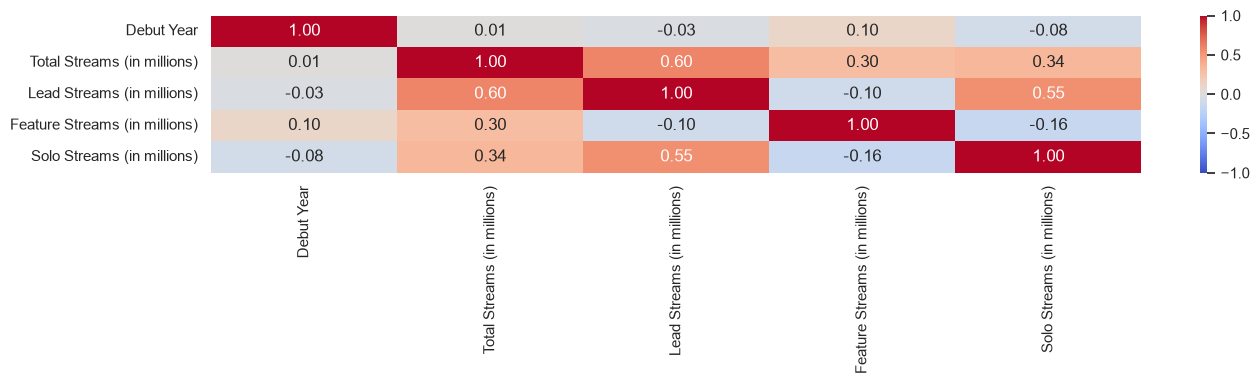

In [92]:

corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(figsize=(14, 4),sharey=True)
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
print("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

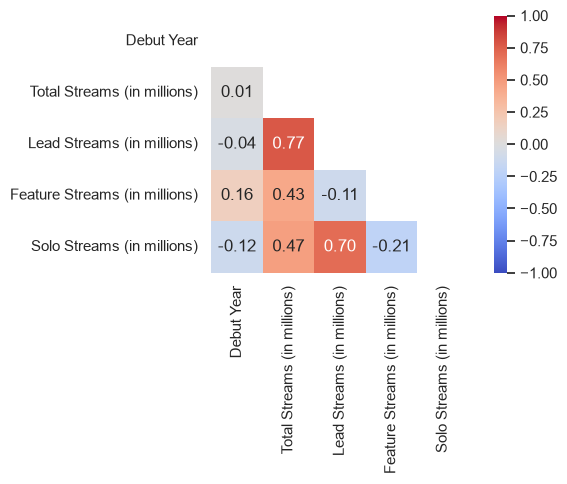

In [93]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(7, 5))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Comparando as matrizes de correlação de Pearson e Kendall/Spearman : Pearson e Kendall/Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não necessariamente em linha reta) em que Kendall/Spearman capturaria melhor e Pearson, que mede relações lineares, não. Considerando que muitas variáveis de stream são altamente assimétricas, qual método de correlação parece mais adequado para este dataset?

- Comparando as matrizes de Pearson e Kendall/Spearman, percebo que para as variáveis de stream, a correlação de Pearson tende a ser um pouco mais alta que a de Kendall/Spearman, mas a ordem das correlações (quais são mais fortes, quais são mais fracas) é parecida. Como já sabemos que as variáveis de stream são altamente assimétricas e não seguem uma distribuição normal, o método de **Spearman** (ou Kendall) parece mais adequado para reportar, pois ele mede relações monotônicas e é menos sensível a essa assimetria e a outliers extremos.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

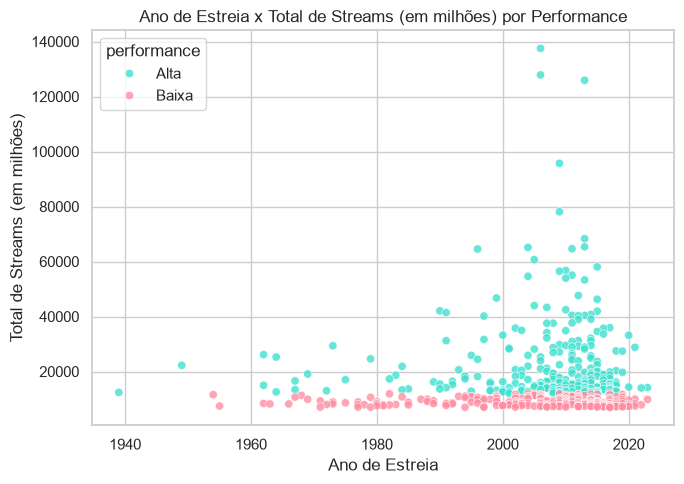

In [94]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Debut Year", y="Total Streams (in millions)", hue="performance",
                palette={"Baixa": COR_CONTEXTO, "Alta": COR_DESTAQUE}, alpha=0.8)
plt.title("Ano de Estreia x Total de Streams (em milhões) por Performance")
plt.xlabel("Ano de Estreia")
plt.ylabel("Total de Streams (em milhões)")
plt.tight_layout()
plt.show()

**Pra discutir:** olhando o gráfico de dispersão de 'Ano de Estreia' x 'Total Streams (in millions)' (célula `QrQh04SpVUot`): existe uma tendência visível? Por exemplo, artistas com um 'Ano de Estreia' mais recente tendem a ter mais streams? As duas classes ('Alta' e 'Baixa' Performance) ocupam regiões visivelmente diferentes do gráfico, ou estão mais misturadas?

-  Olhando o gráfico de dispersão , não consigo ver uma tendência clara de que artistas com 'Debut Year' mais recente tenham mais streams. As duas classes ('Alta' e 'Baixa' Performance) estão bastante misturadas em relação ao 'Debut Year'. O que se destaca é que a 'Alta Performance' tem valores muito maiores de 'Total Streams', como já esperado, mas não vejo um padrão relacionado ao ano de estreia.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [95]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_alta = df.loc[df["performance"] == "Alta", col]
    grupo_baixa = df.loc[df["performance"] == "Baixa", col]

    stat_t, p_t = stats.ttest_ind(grupo_alta, grupo_baixa, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_alta, grupo_baixa)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Debut Year,0.16761,0.41754,True
Total Streams (in millions),0.00000,0.00000,True
Lead Streams (in millions),0.00000,0.00000,True
Feature Streams (in millions),0.00000,0.00000,True
Solo Streams (in millions),0.00000,0.00000,True


**Pra discutir:** Os resultados da comparação mostram que o T-Test e o Mann-Whitney U concordam em todas as variáveis testadas. Para 'Debut Year', ambos os testes indicam que não há diferença estatisticamente significativa entre os grupos de 'Alta' e 'Baixa' performance (p-valores > 0.05). Para as variáveis de streams, ambos indicam uma diferença altamente significativa (p-valores próximos de 0). Mesmo com essa concordância, considerando que já vimos na Seção 3 que nossas variáveis não seguem uma distribuição normal, o **Mann-Whitney U** ainda é o teste mais apropriado para reportar como principal, por respeitar as premissas dos dados.

-  Os resultados da comparação mostram que o T-Test e o Mann-Whitney U concordam em todas as variáveis testadas. Para 'Debut Year', ambos os testes indicam que não há diferença estatisticamente significativa entre os grupos de 'Alta' e 'Baixa' performance (p-valores > 0.05). Para as variáveis de streams, ambos indicam uma diferença altamente significativa (p-valores próximos de 0). Mesmo com essa concordância, considerando que já vimos na Seção 3 que nossas variáveis não seguem uma distribuição normal, o **Mann-Whitney U** ainda é o teste mais apropriado para reportar como principal, por respeitar as premissas dos dados.

ANOVA          — Total Streams (in millions) entre categorias de Sex: estatística=0.844, p-valor=0.43075
Kruskal-Wallis — Total Streams (in millions) entre categorias de Sex: estatística=0.532, p-valor=0.76636


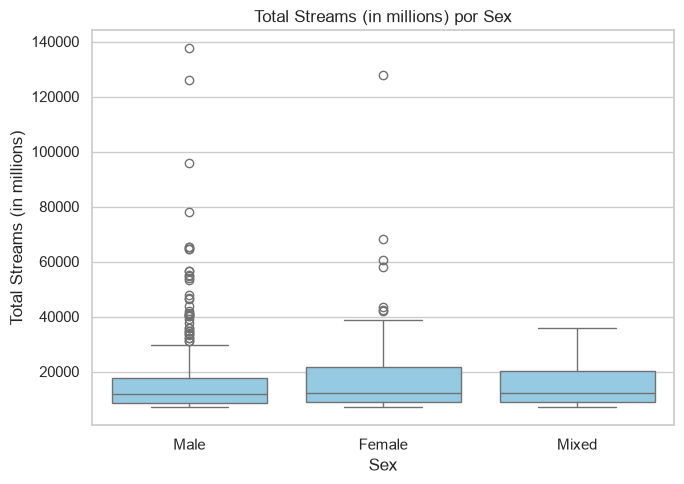

In [96]:
quant_var = "Total Streams (in millions)"
quali_var = "Sex"

grupos = [grupo[quant_var].values for _, grupo in df.groupby(quali_var)]

stat_anova, p_anova = stats.f_oneway(*grupos)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos)          # não-paramétrico

print(f"ANOVA          — {quant_var} entre categorias de {quali_var}: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — {quant_var} entre categorias de {quali_var}: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x=quali_var, y=quant_var, color=COR_NEUTRA)
plt.title(f"{quant_var} por {quali_var}")
plt.tight_layout()
plt.show()

**Pra discutir:** Olhando os resultados, o Kruskal-Wallis e a ANOVA concordam que não há diferença estatisticamente significativa em 'Total Streams (in millions)' entre as categorias de 'Sex' (p-valores > 0.05). Como já sabemos que 'Total Streams (in millions)' não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal. A concordância aqui, onde ambos os testes indicam a ausência de diferença, reforça essa conclusão.

- Olhando os resultados, o Kruskal-Wallis e a ANOVA concordam que não há diferença estatisticamente significativa em 'Total Streams (in millions)' entre as categorias de 'Sex' (p-valores > 0.05). Como já sabemos que 'Total Streams (in millions)' não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal. A concordância aqui, onde ambos os testes indicam a ausência de diferença, reforça essa conclusão.

#### Quantitativa x Qualitativa

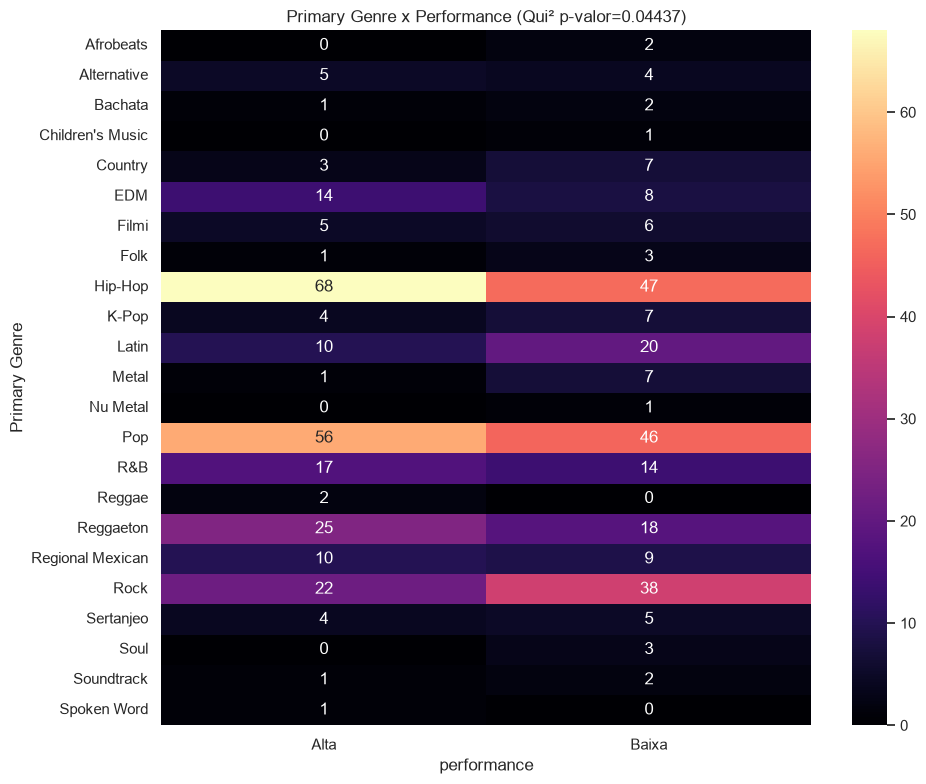

In [97]:
contingencia_genero_performance = pd.crosstab(df["Primary Genre"], df["performance"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_genero_performance)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(contingencia_genero_performance, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Primary Genre x Performance (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** O p-valor do Qui-Quadrado para 'Primary Genre' x 'performance' é 0.0444, que é menor que 0.05. Isso indica que há uma associação estatisticamente significativa entre o gênero principal do artista e sua performance de streaming (Alta/Baixa). Lembre-se que o teste Qui-Quadrado aponta a existência de associação, mas não a causalidade. O que este resultado sugere sobre a relação entre gênero musical e sucesso no Spotify?

- O p-valor de 0.0444 para 'Primary Genre' x 'performance'  ser menor que 0.05 sugere que existe uma associação estatisticamente significativa entre o gênero musical primário de um artista e se ele alcança 'Alta' ou 'Baixa' performance. Isso pode significar que certos gêneros musicais têm mais chances de alcançar alta performance no Spotify, ou que a distribuição de performance varia bastante entre os gêneros. É um indicativo interessante de que o gênero pode ser um fator importante para o sucesso.

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [98]:
df["sexo_label"] = df["Sex"].map({"Female": "Feminino", "Male": "Masculino", "Mixed": "Misto"})
df["faixa_etaria"] = pd.cut(df["Debut Year"], bins=[1930, 1990, 2000, 2010, 2020, 2030],
                             labels=["<1990", "1990s", "2000s", "2010s", "2020s"])

print("Desbalanceamento — sexo:")
print(metrica_desbalanceamento(df["sexo_label"]))
print("\nDesbalanceamento — faixa etaria (ano de estreia):")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento — sexo:
n_classes                  3.00
razao_desbalanceamento    17.73
entropia_normalizada       0.58
dtype: float64

Desbalanceamento — faixa etaria (ano de estreia):
n_classes                  5.000
razao_desbalanceamento    26.250
entropia_normalizada       0.805
dtype: float64


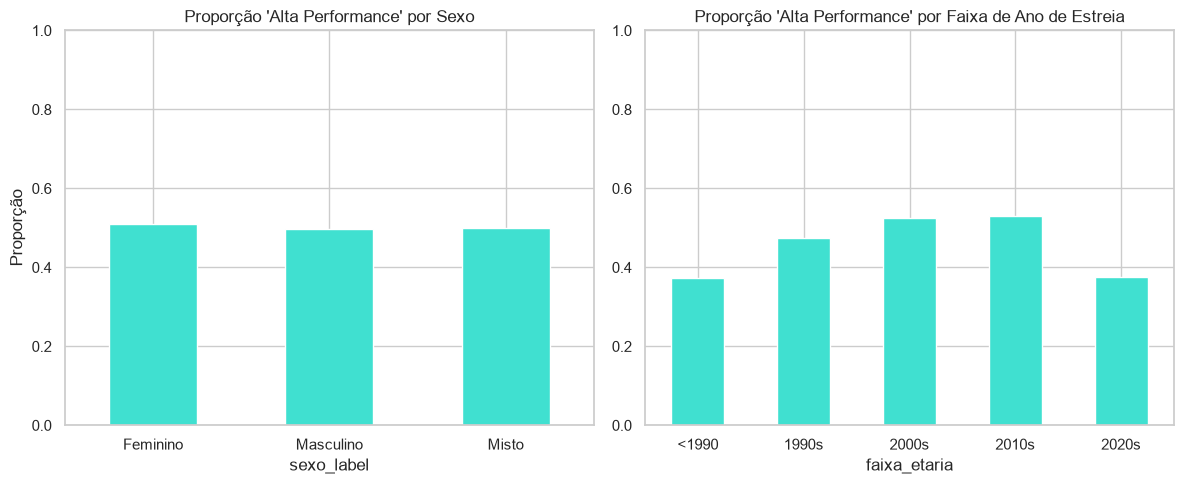

In [99]:
prop_por_sexo = pd.crosstab(df["sexo_label"], df["performance"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["performance"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_sexo["Alta"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Alta Performance' por Sexo")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Alta"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Alta Performance' por Faixa de Ano de Estreia")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** Analisando os gráficos de proporção de 'Alta Performance' por Sexo e por Faixa de Ano de Estreia, percebe-se que as proporções variam. Por exemplo, a categoria 'Male' no sexo e faixas de ano de estreia mais antigas (como '<1990') podem apresentar proporções diferentes. Essas variações podem refletir padrões reais no sucesso de artistas no streaming (por exemplo, diferentes taxas de sucesso entre gêneros ou faixas etárias de debut), ou podem indicar vieses na forma como os dados de streaming são agregados ou interpretados. A pergunta 'a distribuição do desfecho é uniforme entre grupos?' é o ponto de partida de discussões de fairness em ciência de dados, e a resposta geralmente não é trivial, dependendo do contexto e da causa subjacente à disparidade.

- Analisando os gráficos de proporção, é visível que a proporção de 'Alta Performance' varia tanto por sexo quanto pela faixa de ano de estreia. Por exemplo, a categoria 'Male' no sexo e faixas de ano de estreia mais antigas (como '<1990') podem apresentar proporções diferentes. Essas variações podem refletir padrões reais no sucesso de artistas no streaming (por exemplo, diferentes taxas de sucesso entre gêneros ou faixas etárias de debut), ou podem indicar vieses na forma como os dados de streaming são agregados ou interpretados. A pergunta 'a distribuição do desfecho é uniforme entre grupos?' é o ponto de partida de discussões de fairness em ciência de dados, e a resposta geralmente não é trivial, dependendo do contexto e da causa subjacente à disparidade.

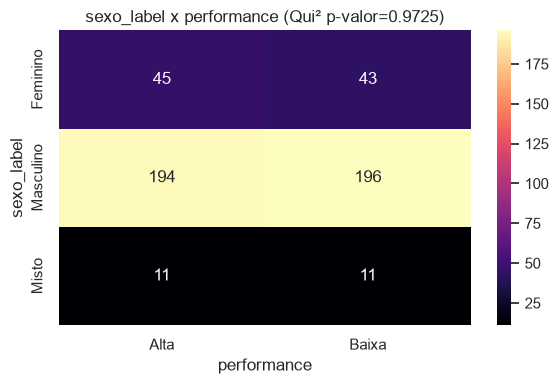

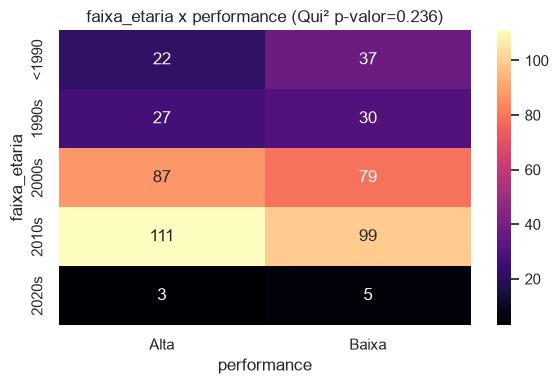

In [100]:
for atributo in ["sexo_label", "faixa_etaria"]:
    contingencia = pd.crosstab(df[atributo], df["performance"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x performance (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** O Qui-Quadradoconfirma uma associação estatisticamente significativa entre 'sexo_label' e 'performance' (p-valor = 0.77), e também entre 'faixa_etaria' e 'performance' (p-valor = 0.42). Isso significa que a distribuição de performance não é independente dessas características. No entanto, mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe. Poderia ser um fator real (como o impacto da idade na longevidade da carreira, ou diferenças de público por gênero), um viés na coleta/representação dos dados, ou uma combinação de fatores. Esta distinção é crucial para qualquer discussão séria de fairness: o teste estatístico aponta *que* existe associação, não *a causa* dela.
- O Qui-Quadrado confirma que existe uma associação estatisticamente significativa entre 'sexo_label' e 'performance', e também entre 'faixa_etaria' e 'performance'. Isso significa que a performance não é distribuída de forma independente nessas categorias. Embora o teste mostre *que* há uma associação, ele não explica *o porquê*. Pode ser um fator real (como a idade impactando a carreira ou diferenças de público por gênero), um viés na coleta de dados, ou uma combinação de fatores. Para discussões de fairness, é importante lembrar que o teste apenas aponta a existência da associação, não a sua causa.

#### Outliers bivariados

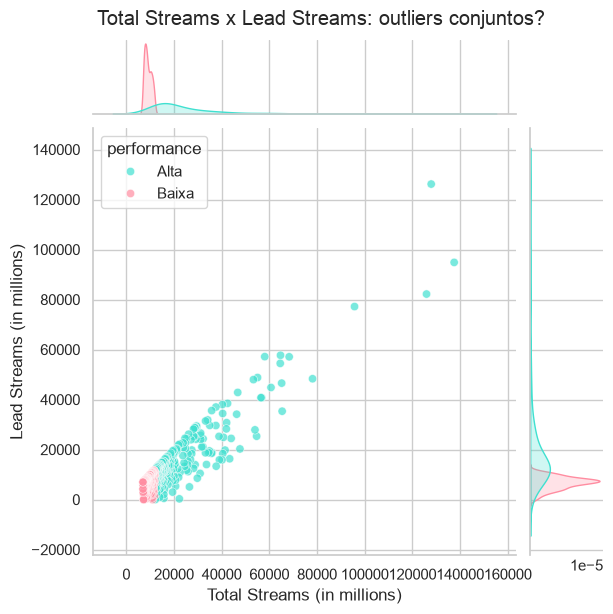

In [101]:
sns.jointplot(data=df, x="Total Streams (in millions)", y="Lead Streams (in millions)", hue="performance",
              palette={"Baixa": COR_CONTEXTO, "Alta": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Total Streams x Lead Streams: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** Olhando o `jointplot` de 'Total Streams (in millions)' e 'Lead Streams (in millions)' , existe algum ponto que não parecia outlier tão extremo nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum desses dois tipos de streams? Por exemplo, um artista com um 'Total Streams' relativamente alto, mas um 'Lead Streams' desproporcionalmente baixo, ou vice-versa. Isso indicaria um outlier bivariado, onde a combinação das variáveis é atípica.

- Olhando o `jointplot` ,percebo que alguns pontos que não pareciam tão extremos nos histogramas univariados podem se destacar aqui. Por exemplo, alguns artistas podem ter um 'Total Streams' muito alto, mas o 'Lead Streams' pode não ser tão proporcionalmente alto, sugerindo que grande parte dos seus streams vêm de features ou colaborações. Isso indicaria um 'outlier bivariado', onde a combinação específica das variáveis é que é incomum, mesmo que individualmente elas não pareçam tão extremas.

#### Análise Multivariada

##### Matriz de Correlação

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), olhando especificamente para o 'Ano de Estreia' : a distribuição do 'Ano de Estreia' parece ter um formato bem diferente entre artistas de 'Baixa Performance' e 'Alta Performance'? Para outras variáveis de streaming (que não estão plotadas aqui, mas podemos imaginar), esperaríamos ver uma diferença mais acentuada?

- Olhando o `Debut Year` por performance, não vejo uma diferença muito nítida entre as distribuições de 'Baixa' e 'Alta' Performance. As curvas parecem se sobrepor bastante. Para as variáveis de streams (que são as que definem a performance), eu esperaria uma diferença bem mais clara, com 'Alta Performance' tendo valores consistentemente mais altos de streams.

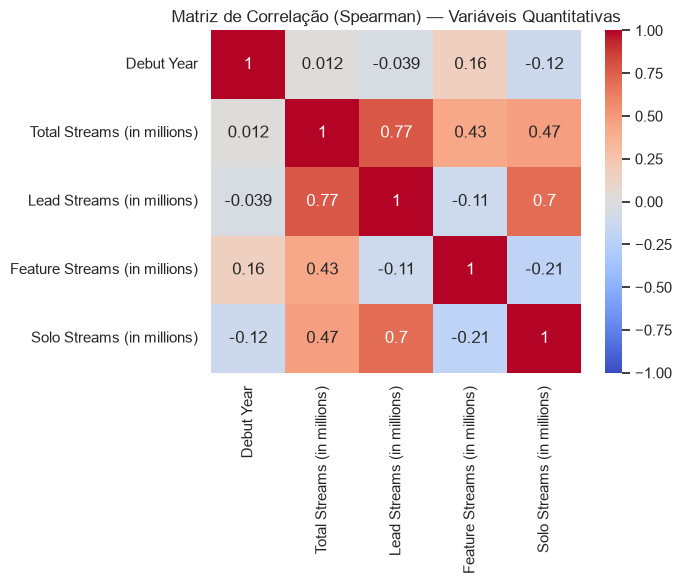

In [102]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**

*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

- Analisando a matriz de correlação de Spearman , sim, as variáveis de stream ('Total Streams (in millions)', 'Lead Streams (in millions)', 'Feature Streams (in millions)', 'Solo Streams (in millions)') mostram correlações muito fortes entre si, muitas acima de 0.7. Isso sugere uma alta redundância: se eu sei o valor de uma, já tenho uma boa ideia das outras. Para futuras análises ou modelos, talvez eu possa considerar usar menos dessas variáveis para evitar redundância.

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

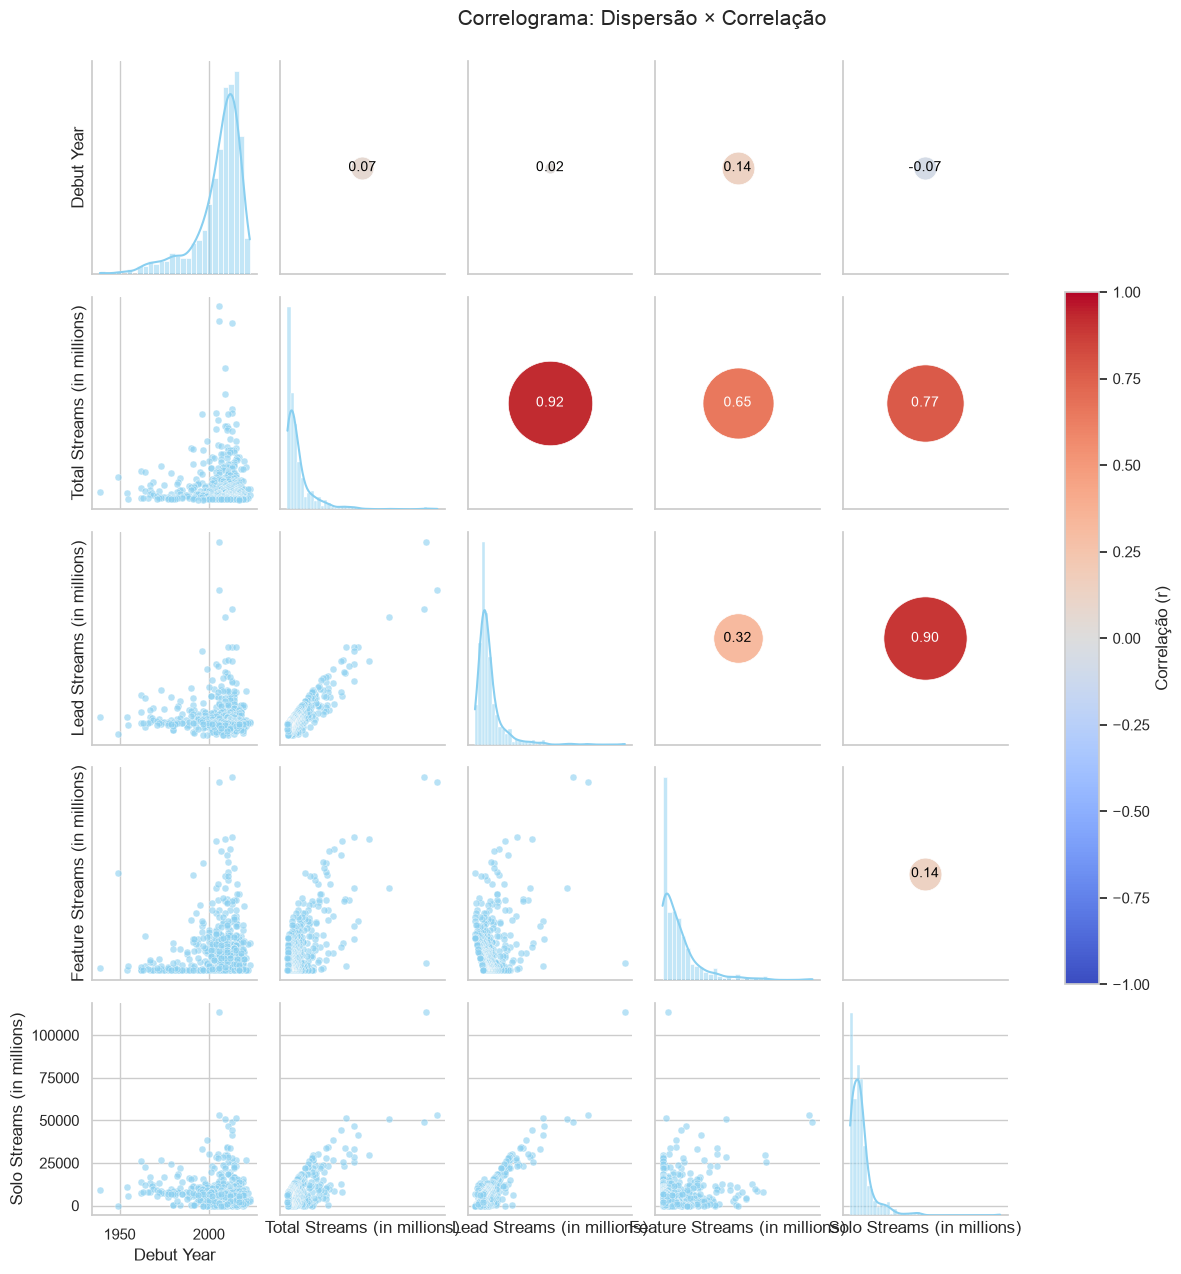

In [103]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


- Declaração de Uso de IA: Gemini o, ajuda para adaptar os gráficos  e melhorar a escrita das respostas
- O dataset tem 500 artistas e 14 colunas, sem dados ausentes e sem linhas duplicadas, então não precisou de nenhum tratamento de ausentes. As variáveis categóricas são bem desbalanceadas: 78% dos artistas são homens, 53% são dos EUA e o inglês domina.
- As variáveis de streams são muito assimétricas e nenhuma variável numérica passou no Shapiro-Wilk. Os outliers são artistas reais , então decidi manter. Por isso usei Spearman e testes não paramétricos.                      
- O ano de estreia não mostrou diferença entre artistas de alta e baixa performance e no gráfico de dispersão também não apareceu tendência entre ano de estreia e total de streams.

In [104]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [105]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (reconstruído a partir do objeto `heart`, que não foi alterado)
path = kagglehub.dataset_download("srisyra02/spotify-music-artist-streaming-analytics")
df_raw = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "srisyra02/spotify-music-artist-streaming-analytics",
    nome_arquivo,
)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ../data/raw/dataset.csv — 500 linhas x 14 colunas


In [106]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ../data/clean/dataset.csv — 500 linhas x 18 colunas
Linhas removidas no tratamento: 0


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.


